# Blocking

Pair completeness (share of labelled matches kept) against the number of candidate pairs.
The course target is a pair completeness above 0.97.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
PAIRS = ["wikidata-ror", "deqar-ror"]

In [2]:
blocking = pd.read_csv("results/blocking.csv")
blocking = blocking[blocking["pair_completeness"].notna() & (blocking["seconds"].notna())]
blocking["pair_completeness"] = blocking["pair_completeness"].astype(float)
blocking.head()

,round,pair,blocker,candidates,pair_completeness,reduction_ratio,seconds,note
1,1,wikidata-ror,standard: exercise key (2 letters x 3 words),238020,0.8105,0.999652,0.6,NaN
2,1,wikidata-ror,standard: normalised name,10626,0.7516,0.999984,0.2,NaN
3,1,wikidata-ror,"sorted neighbourhood: name, window 20",481875,0.8758,0.999295,0.4,NaN
6,1,deqar-ror,standard: exercise key (2 letters x 3 words),56213,0.5724,0.999792,0.2,NaN
7,1,deqar-ror,standard: normalised name,2399,0.5132,0.999991,0.4,NaN


## Pair completeness per blocker

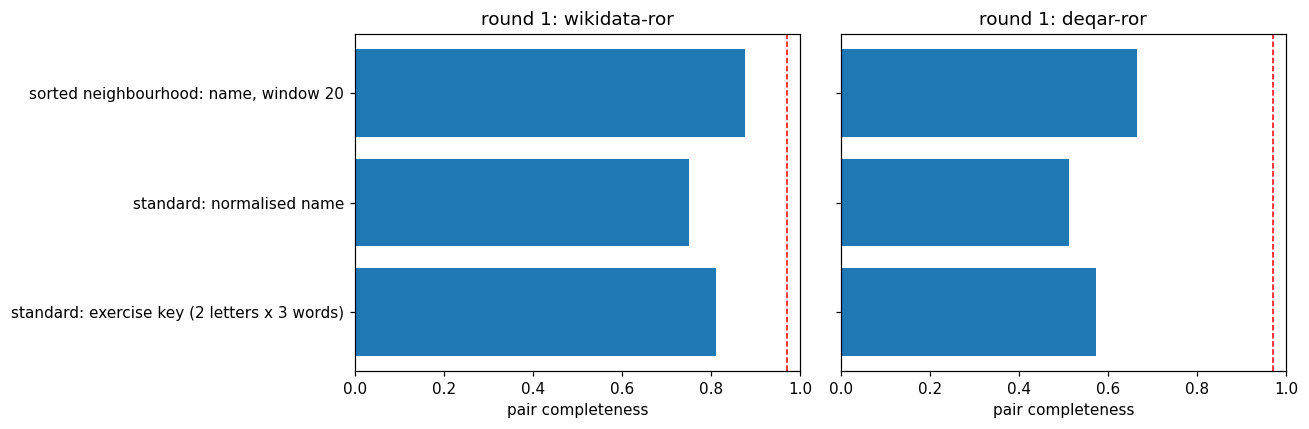

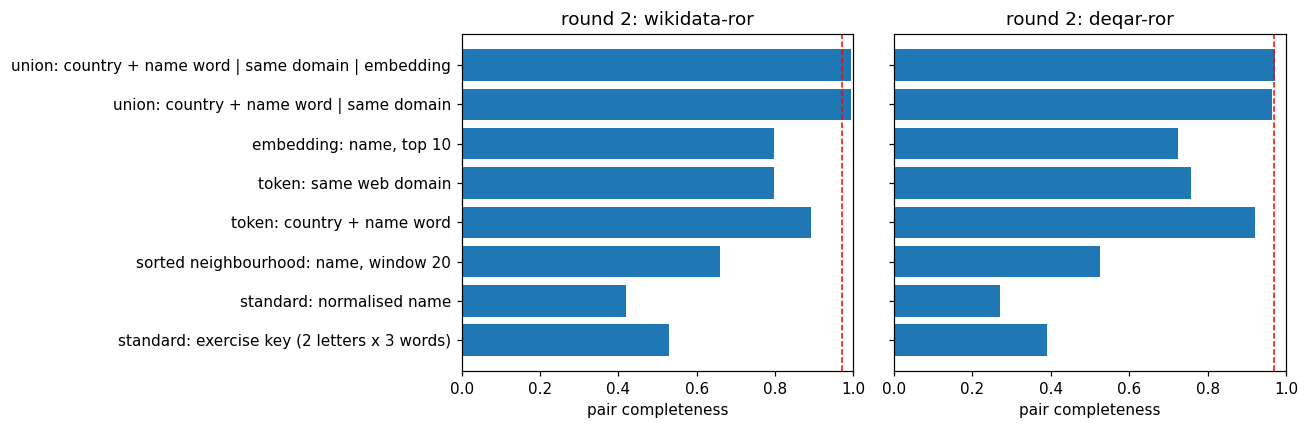

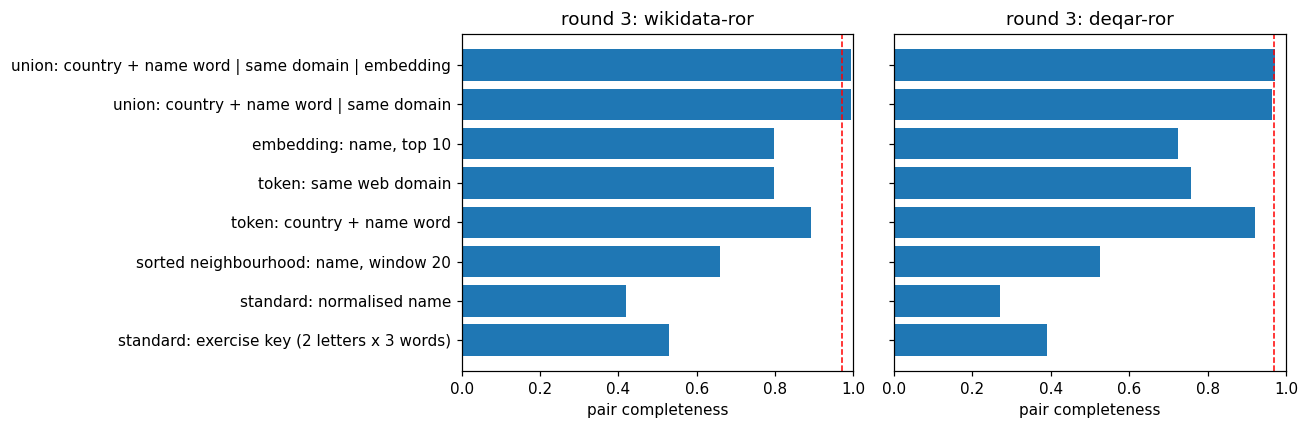

In [3]:
for rnd in sorted(blocking["round"].unique()):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
    for ax, pair in zip(axes, PAIRS):
        part = blocking[(blocking["round"] == rnd) & (blocking["pair"] == pair)]
        ax.barh(part["blocker"], part["pair_completeness"], color="tab:blue")
        ax.axvline(0.97, color="red", linestyle="--", linewidth=1)
        ax.set_xlim(0, 1)
        ax.set_title(f"round {rnd}: {pair}")
        ax.set_xlabel("pair completeness")
    for ax in axes[1:]:
        ax.set_yticklabels([])
    plt.tight_layout()

## Candidate pairs against pair completeness (round 2)

Top left is best: few pairs, most matches kept.

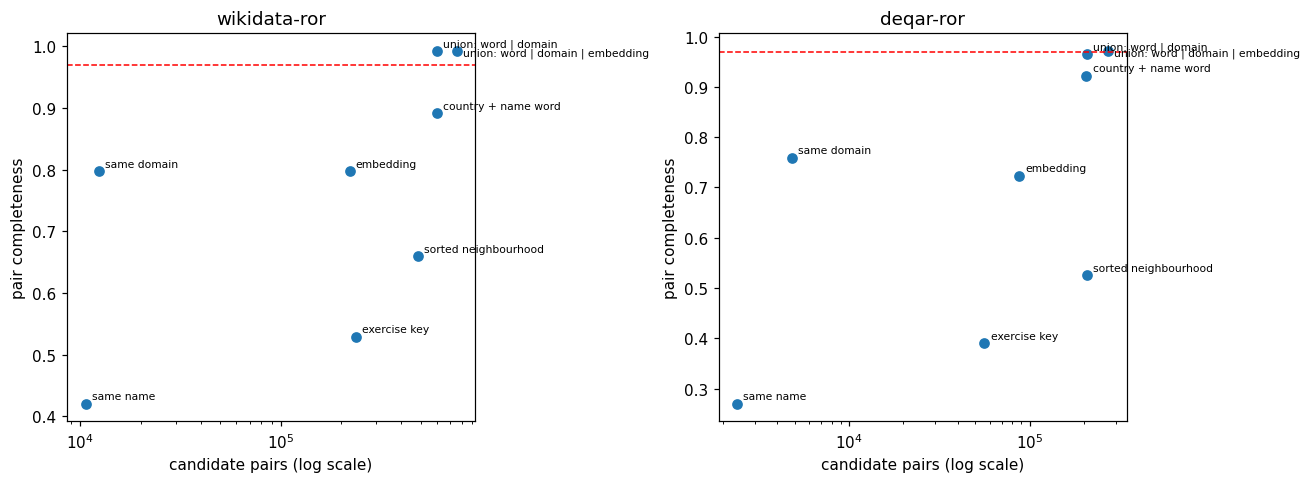

In [4]:
SHORT = {
    "standard: exercise key (2 letters x 3 words)": "exercise key",
    "standard: normalised name": "same name",
    "sorted neighbourhood: name, window 20": "sorted neighbourhood",
    "token: country + name word": "country + name word",
    "token: same web domain": "same domain",
    "embedding: name, top 10": "embedding",
    "union: country + name word | same domain": "union: word | domain",
    "union: country + name word | same domain | embedding": "union: word | domain | embedding",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pair in zip(axes, PAIRS):
    part = blocking[(blocking["round"] == 2) & (blocking["pair"] == pair)]
    ax.scatter(part["candidates"], part["pair_completeness"])
    for _, r in part.iterrows():
        ax.annotate(SHORT.get(r["blocker"], r["blocker"]), (r["candidates"], r["pair_completeness"]),
                    fontsize=7, xytext=(4, -3 if "embedding" in r["blocker"] and "union" in r["blocker"] else 3),
                    textcoords="offset points")
    ax.axhline(0.97, color="red", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_xlabel("candidate pairs (log scale)")
    ax.set_ylabel("pair completeness")
    ax.set_title(pair)
plt.tight_layout()